# Top 300 Anime Database: Cleaning & Exploratory Analysis

## Overview
This notebook takes a **raw, messy** spreadsheet of the top 300 anime, cleans it step by step, and then explores it with four charts.

**Questions explored**
1. Which studios earn the largest share of the estimated revenue?
2. How do anime ratings change with release year?
3. Which are the 10 highest-rated anime, and which studios made them?
4. Which genres appear most often?

## Dataset
| Column | Description |
|---|---|
| `Anime Name` | Title of the anime |
| `Studio` | Producing studio(s); several studios are separated by commas |
| `Rating` | Score out of 10 (stored as text such as `9.1/10` in the raw file) |
| `Release Year` | Year of release (entered in mixed formats in the raw file) |
| `Episodes` | Number of episodes (stored as text such as `24 eps`) |
| `Genre` | Genre tags separated by commas |
| `Revenue Collection` | Estimated revenue as free text (for example `~$350M+ (Franchise/Media Est.)`) |

## Table of contents
1. [Setup and loading the data](#1.-Setup-and-loading-the-data)
2. [Data cleaning](#2.-Data-cleaning)
3. [Studio revenue analysis](#3.-Studio-revenue-analysis)
4. [Visualisations](#4.-Visualisations)

## Assumptions made in this notebook
- Missing **Rating**, **Episodes** and **Release Year** values are filled with the column **median**.
- Missing **Studio** values are labelled `Unknown`.
- When an anime appears more than once, the row that has a rating is kept.
- When an anime has several studios, its revenue is **split equally** between them.
- Revenue is converted to **millions of US dollars** (`Revenue_USD_M`).

> **How to run:** put the Excel file in the same folder as this notebook, then choose **Run All**. The cells depend on each other, so run them from top to bottom.

---
# 1. Setup and loading the data

## 1.1 Import libraries and set the file path

In [1]:
%pip install matplotlib openpyxl

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt

# Path to the raw Excel file (keep it in the same folder as this notebook)
DATA_PATH = "Raw & Messy Top 300 Anime Database (Complete).xlsx"

Matplotlib is building the font cache; this may take a moment.


## 1.2 Load the raw data

In [3]:
# Read the raw spreadsheet into a DataFrame
df = pd.read_excel(DATA_PATH)

print(f"Rows: {df.shape[0]}  |  Columns: {df.shape[1]}")
df.head(10)

Rows: 315  |  Columns: 12


,Anime Name,Studio,Director's Name,Manga Author,Rating,Release Year,Completed or Not,Episodes,Seasons,Genre,Revenue Collection,Streaming Platform
0,Yu-Gi-Oh! Duel Monsters,Studio Gallop,Kunihisa Sugishima,kazuki takahashi,7.55,Spring 2000,COMPLETED,224.0,5.0,"Action, Fantasy, Game",~$11.0B+ (Franchise Total),"netflix, crunchyroll, hulu"
1,bleach,Studio Pierrot,Noriyuki Abe,Tite Kubo,TBD,2004.0,completed,366.0,16.0,"Action, Adventure, Supernatural",~$2.5B+ (Franchise Total),"HULU, DISNEY+"
2,MOBILE SUIT GUNDAM: IRON-BLOODED ORPHANS,Sunrise,TATSUYUKI NAGAI,"original anime (hajime yatate, yoshiyuki tomino)",8.06,2015-01-04 00:00:00,completed,50.0,2.0,"Action, Drama, Mecha, Sci-Fi",~$26.0B+ (Gundam Franchise Total),"Netflix, Crunchyroll, Hulu"
3,BERSERK (1997),NaN,naohito takahashi,Kentaro Miura,8.57,1997.0,Completed,25.0,1.0,"ACTION, DARK FANTASY, HORROR",~$300M+ (Franchise Est.),"Netflix, Crunchyroll"
4,Dr. STONE,TMS Entertainment,"SHINYA IINO, SHUHEI MATSUSHITA","Riichiro Inagaki, Boichi",8.27,2019.0,Ongoing,58.0,3.0,"Adventure, Comedy, Sci-Fi",~$160M+ (Franchise Est.),"Crunchyroll, Max"
5,Macross (Super Dimension Fortress Macross),NaN,NOBORU ISHIGURO,"Shoji Kawamori, Studio Nue",NaN,1982-10-01 00:00:00,Finished,NaN,1.0,NaN,NaN,"Disney+,Amazon Prime Video"
6,Your Lie in April,A-1 Pictures,KYOHEI ISHIGURO,Naoshi Arakawa,8.64,2014-01-04 00:00:00,COMPLETED,22 eps,1.0,"Drama, Music, Romance",~$70M+ (Media/Manga Est.),"Crunchyroll,Hulu"
7,steins;gate,White Fox,"hiroshi hamasaki, takuya sato",Original Visual Novel (5pb. / Nitroplus),9.07,2011.0,COMPLETED,24.0,1.0,"drama, sci-fi, psychological thriller",~$120M+ (Franchise Est.),Crunchyroll
8,Kill la Kill,Studio Trigger,Hiroyuki Imaishi,Original Anime (Kazuki Nakashima / Trigger),8.03,13,COMPLETED,24.0,1.0,"action, comedy, sci-fi",~$95M+ (Franchise Est.),"Crunchyroll, Hulu"
9,hajime no ippo,NaN,"SATOSHI NISHIMURA, JUN SHISHIDO",George Morikawa,NaN,2000-01-04 00:00:00,Completed,NaN,3.0,NaN,NaN,"NETFLIX, CRUNCHYROLL"


## 1.3 Inspect data types and missing values
Before cleaning, check which columns hold text instead of numbers and how many values are missing.

In [4]:
# Column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 315 entries, 0 to 314
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Anime Name          315 non-null    object
 1   Studio              277 non-null    object
 2   Director's Name     315 non-null    object
 3   Manga Author        315 non-null    object
 4   Rating              278 non-null    object
 5   Release Year        315 non-null    object
 6   Completed or Not    315 non-null    object
 7   Episodes            283 non-null    object
 8   Seasons             315 non-null    object
 9   Genre               290 non-null    object
 10  Revenue Collection  293 non-null    object
 11  Streaming Platform  315 non-null    object
dtypes: object(12)
memory usage: 29.7+ KB


---
# 2. Data cleaning
Each step below fixes one problem in the raw data. All steps use plain string methods, with no regular expressions, to keep the code easy to read.

## 2.1 Standardise text columns
**Problem:** names, studios and genres have inconsistent capitalisation, extra spaces and uneven comma spacing.

**Fix:** trim spaces, convert to Title Case, put exactly one space after each comma, and collapse repeated spaces.

In [5]:
def tidy_text(series, fix_commas=False):
    """Trim spaces, apply Title Case and collapse repeated whitespace.

    If fix_commas is True, make sure every comma is followed by one space
    so that multi-value cells look like "A, B, C".
    """
    series = series.str.strip().str.title()
    if fix_commas:
        series = series.str.replace(",", ", ", regex=False)
    # split() + join() turns any run of spaces into a single space
    return series.str.split().str.join(" ")


df["Anime Name"] = tidy_text(df["Anime Name"])
df["Studio"] = tidy_text(df["Studio"], fix_commas=True)
df["Genre"] = tidy_text(df["Genre"], fix_commas=True)
df["Revenue Collection"] = df["Revenue Collection"].str.strip()

# Quick check of the cleaned columns
df[["Anime Name", "Studio", "Genre"]].head(10)

,Anime Name,Studio,Genre
0,Yu-Gi-Oh! Duel Monsters,Studio Gallop,"Action, Fantasy, Game"
1,Bleach,Studio Pierrot,"Action, Adventure, Supernatural"
2,Mobile Suit Gundam: Iron-Blooded Orphans,Sunrise,"Action, Drama, Mecha, Sci-Fi"
3,Berserk (1997),NaN,"Action, Dark Fantasy, Horror"
4,Dr. Stone,Tms Entertainment,"Adventure, Comedy, Sci-Fi"
5,Macross (Super Dimension Fortress Macross),NaN,NaN
6,Your Lie In April,A-1 Pictures,"Drama, Music, Romance"
7,Steins;Gate,White Fox,"Drama, Sci-Fi, Psychological Thriller"
8,Kill La Kill,Studio Trigger,"Action, Comedy, Sci-Fi"
9,Hajime No Ippo,NaN,NaN


## 2.2 Convert Rating and Episodes to numbers
**Problem:** ratings look like `9.1/10` and episode counts like `24 eps`, so both are stored as text.

**Fix:** remove the unit text and convert the rest to numbers. Values that cannot be converted become `NaN` (missing) and are handled in step 2.4.

In [6]:
# --- Rating: "9.1/10" -> 9.1 ---
rating_clean = (
    df["Rating"]
    .astype(str)
    .str.strip()
    .str.replace("/10", "", regex=False)
    .str.strip()
)
df["Rating"] = pd.to_numeric(rating_clean, errors="coerce")

# --- Episodes: "24 eps" / "1 ep" -> 24 / 1 ---
# "eps" is removed before "ep" so that no stray "s" is left behind
ep_clean = (
    df["Episodes"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace("eps", "", regex=False)
    .str.replace("ep", "", regex=False)
    .str.strip()
)
df["Episodes"] = pd.to_numeric(ep_clean, errors="coerce").astype("Int64")

# Quick check
df[["Rating", "Episodes"]].head(10)

,Rating,Episodes
0,7.55,224
1,NaN,366
2,8.06,50
3,8.57,25
4,8.27,58
5,NaN,<NA>
6,8.64,22
7,9.07,24
8,8.03,24
9,NaN,<NA>


## 2.3 Extract a clean Release Year
**Problem:** release years are entered in several formats, for example `2004`, `2004-05-01`, `2004/05` or a two-digit year such as `04`.

**Fix:** try three strategies in order and use the first one that works:
1. A four-digit year between 1900 and 2030.
2. A full date, from which the year is read.
3. A two-digit year, where 50 or above means 19xx and below 50 means 20xx.

In [7]:
yr_str = df["Release Year"].astype(str).str.strip()

# Strategy 2: values that look like dates (contain "-" or "/") -> read the year
looks_like_date = yr_str.str.contains("-", regex=False) | yr_str.str.contains("/", regex=False)
dt_year = pd.to_datetime(yr_str.where(looks_like_date), errors="coerce").dt.year

# Split the text into tokens and keep the first number found
yr_tokens = (
    yr_str.str.replace("-", " ", regex=False)
    .str.replace("/", " ", regex=False)
    .str.replace(",", " ", regex=False)
    .str.split()
)
yr_first_num = pd.to_numeric(yr_tokens.str[0], errors="coerce")

# Strategy 1: a plausible four-digit year
yr_4digit = yr_first_num.where((yr_first_num >= 1900) & (yr_first_num <= 2030))

# Strategy 3: a two-digit year (50-99 -> 1950-1999, 00-49 -> 2000-2049)
yr_2digit = yr_first_num.where((yr_first_num >= 0) & (yr_first_num < 100))
yr_2digit_full = yr_2digit.where(
    yr_2digit.isna(),
    np.where(yr_2digit >= 50, yr_2digit + 1900, yr_2digit + 2000),
)

# Combine: use strategy 1, fall back to 2, then to 3
df["Release Year"] = (
    yr_4digit.fillna(dt_year).fillna(pd.Series(yr_2digit_full)).astype("Int64")
)

# Quick check
df["Release Year"].head(10)

0    <NA>
1    2004
2    2015
3    1997
4    2019
5    1982
6    2014
7    2011
8    2013
9    2000
Name: Release Year, dtype: Int64

## 2.4 Remove duplicates and fill missing values
**Problem:** some anime appear more than once, and some Studio, Rating, Episodes and Release Year values are missing.

**Fix:**
- Sort so that rows **with** a rating come first, then keep the first row for each anime name.
- Fill missing studios with `Unknown`, and missing numbers with the column median.

In [8]:
rows_before = len(df)

# Helper column: 1 if the row has a rating, 0 if not (used only for sorting)
df["_has_rating"] = df["Rating"].notna().astype(int)

df = (
    df.sort_values("_has_rating", ascending=False)   # rows with a rating first
    .drop_duplicates(subset=["Anime Name"], keep="first")
    .drop(columns=["_has_rating"])                   # helper no longer needed
    .reset_index(drop=True)
)
print(f"Duplicates removed: {rows_before - len(df)}  |  Rows remaining: {len(df)}")

# Fill missing values
df["Studio"] = df["Studio"].fillna("Unknown")
df["Rating"] = df["Rating"].fillna(df["Rating"].median())
df["Episodes"] = df["Episodes"].fillna(df["Episodes"].median())
df["Release Year"] = (
    df["Release Year"].fillna(df["Release Year"].median()).astype("Int64")
)

# Quick check
df[["Studio", "Rating", "Episodes", "Release Year"]].head(10)

Duplicates removed: 15  |  Rows remaining: 300


,Studio,Rating,Episodes,Release Year
0,Studio Gallop,7.55,224,2012
1,Naz,7.88,13,2020
2,Mappa,8.07,13,2023
3,A-1 Pictures,8.28,23,2021
4,Olm,7.62,127,2008
5,P.A. Works,7.45,26,2012
6,Studio Trigger,8.58,24,2024
7,Tms Entertainment,7.91,26,2018
8,Bones,9.10,64,2009
9,A-1 Pictures,8.30,12,2016


## 2.5 Convert Revenue Collection to a number (USD millions)
**Problem:** revenue is free text, such as `~$350M+ (Franchise/Media Est.)` or `$1.2B`.

**Fix:** keep only the amount after the `$` sign, remove symbols such as `+` and `,`, then apply a multiplier based on the unit letter:

| Unit | Meaning | Multiplier (to millions) |
|---|---|---|
| `B` | Billion | × 1000 |
| `M` | Million | × 1 |
| `K` | Thousand | × 0.001 |

The result is stored in a new column, `Revenue_USD_M`.

In [9]:
# Isolate the amount: "~$350M+ (Franchise/Media Est.)" -> "350M+"
rev_after_dollar = (
    df["Revenue Collection"]
    .astype(str)
    .str.split("$")
    .str[-1]          # keep the text after the "$"
    .str.split("(")
    .str[0]           # drop any note in brackets
    .str.strip()
)

# Take the first word and remove "+" and "," -> "350M"
rev_token = (
    rev_after_dollar.str.split()
    .str[0]
    .str.replace("+", "", regex=False)
    .str.replace(",", "", regex=False)
)

# Detect the unit letter (B, M or K)
has_b = rev_token.str.upper().str.endswith("B").fillna(False).astype(bool)
has_m = rev_token.str.upper().str.endswith("M").fillna(False).astype(bool)
has_k = rev_token.str.upper().str.endswith("K").fillna(False).astype(bool)

# Remove the unit letter and convert the remaining digits to a number
rev_num_str = (
    rev_token.str.upper()
    .str.replace("B", "", regex=False)
    .str.replace("M", "", regex=False)
    .str.replace("K", "", regex=False)
    .str.strip()
)
rev_num = pd.to_numeric(rev_num_str, errors="coerce")

# Build the multiplier that converts each value to millions of USD
mult = pd.Series(np.nan, index=df.index)
mult = mult.where(~has_b, 1000.0)    # billions  -> millions
mult = mult.where(~has_m, 1.0)       # millions  -> millions
mult = mult.where(~has_k, 0.001)     # thousands -> millions

df["Revenue_USD_M"] = rev_num * mult

# Quick check: original text next to the parsed number
df[["Revenue Collection", "Revenue_USD_M"]].head(10)

,Revenue Collection,Revenue_USD_M
0,~$11.0B+ (Franchise Total),11000.0
1,~$30M+ (Franchise Est.),30.0
2,~$95M+ (Franchise Est.),95.0
3,~$110M+ (Franchise Est.),110.0
4,~$1.3B+ (Franchise Total),1300.0
5,~$45M+ (Franchise Est.),45.0
6,~$85M+ (Media/Manga Est.),85.0
7,~$45M+ (Franchise Est.),45.0
8,~$350M+ (Franchise/Media Est.),350.0
9,~$75M+ (Media/Manga Est.),75.0


---
# 3. Studio revenue analysis
Many anime are made by more than one studio. To avoid counting the same revenue twice, each anime's revenue is **split equally** between its studios before the totals are added up.

## 3.1 Total estimated revenue per studio

In [10]:
# Keep only anime that have a revenue figure
studio_rev_df = df.dropna(subset=["Revenue_USD_M"]).copy()

# Turn "Studio A, Studio B" into a list and split the revenue equally
studio_rev_df["Studio_List"] = studio_rev_df["Studio"].str.split(", ")
studio_rev_df["Split_Rev_M"] = (
    studio_rev_df["Revenue_USD_M"] / studio_rev_df["Studio_List"].str.len()
)

# One row per studio: "explode" turns each list item into its own row
studio_exploded = studio_rev_df.explode("Studio_List")
studio_exploded["Studio_Clean"] = studio_exploded["Studio_List"].str.strip()

# Add up the revenue of every studio, highest first
studio_totals = (
    studio_exploded.groupby("Studio_Clean")["Split_Rev_M"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 studios by estimated revenue (USD millions):")
print(studio_totals.head(10).round(1))

Top 10 studios by estimated revenue (USD millions):
Studio_Clean
Sunrise                 106205.0
Olm                      91462.5
Toei Animation           89230.0
Ufotable                 23000.0
Studio Pierrot           14810.0
Tms Entertainment        12990.0
Unknown                  11930.0
Studio Gallop            11420.0
Tatsunoko Production      8400.0
Gainax                    8030.0
Name: Split_Rev_M, dtype: float64


---
# 4. Visualisations

## 4.1 Pie chart: studio revenue share
Shows how the estimated revenue is shared between the **top 7 studios**. All remaining studios are grouped into one slice called *Other Studios*.

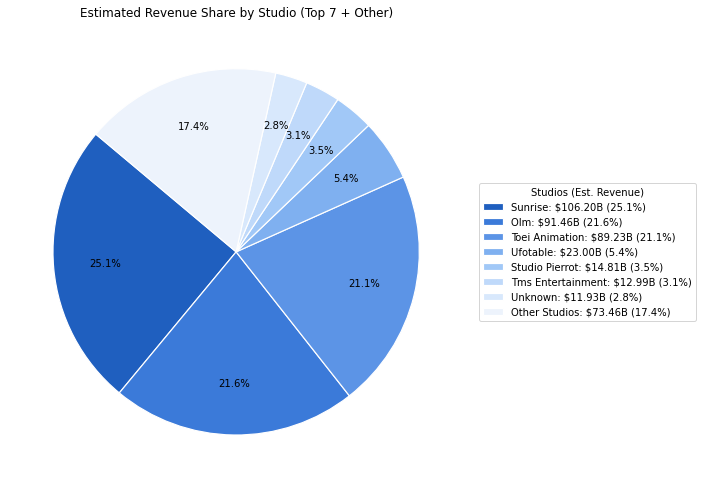

In [11]:
# Top 7 studios + one combined slice for everything else
top7 = studio_totals.head(7)
other_rev = pd.Series({"Other Studios": studio_totals.iloc[7:].sum()})
pie_series = pd.concat([top7, other_rev])

# Shades of blue, darkest for the biggest slice
colors = [
    "#1f5fbf", "#3b7ad9", "#5c94e6", "#7fb0f0",
    "#a1c8f7", "#bfd9fa", "#d8e8fc", "#edf3fc",
]

fig, ax = plt.subplots(figsize=(9, 7))
wedges, texts, autotexts = ax.pie(
    pie_series.values,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    pctdistance=0.72,
    wedgeprops={"edgecolor": "white", "linewidth": 1.2},
)

# Legend text: show billions for large values and millions for small ones
total_rev = pie_series.sum()
legend_labels = [
    f"{name}: ${value / 1000:.2f}B ({value / total_rev * 100:.1f}%)"
    if value >= 1000
    else f"{name}: ${value:.0f}M ({value / total_rev * 100:.1f}%)"
    for name, value in pie_series.items()
]
ax.legend(
    wedges,
    legend_labels,
    title="Studios (Est. Revenue)",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),   # place the legend outside the pie
)

ax.set_title("Estimated Revenue Share by Studio (Top 7 + Other)")
plt.tight_layout()
plt.show()

## 4.2 Scatter plot: release year vs. rating
Each dot is one anime. The dot **colour** shows the number of episodes (capped at 150 so that a few very long series do not dominate the colour scale).

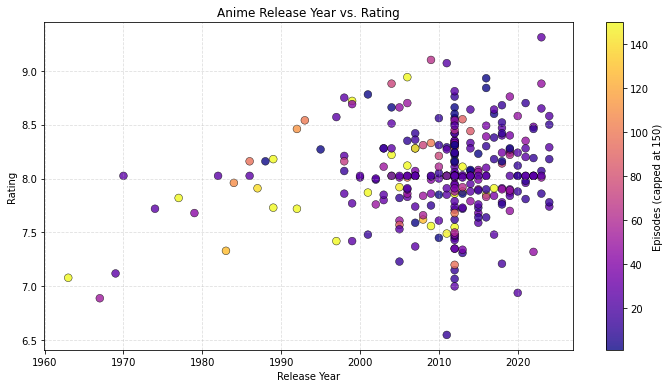

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.5))

scatter = ax.scatter(
    df["Release Year"].astype(float),
    df["Rating"],
    c=df["Episodes"].astype(float).clip(upper=150),   # colour = episodes (max 150)
    cmap="plasma",
    alpha=0.8,
    s=60,
    edgecolors="black",
    linewidth=0.5,
)

fig.colorbar(scatter, ax=ax, label="Episodes (capped at 150)")
ax.set_title("Anime Release Year vs. Rating")
ax.set_xlabel("Release Year")
ax.set_ylabel("Rating")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 4.3 Bar chart: top 10 anime by rating
Ranks anime by rating, using the number of episodes to break ties. The studio is shown in brackets next to each title.

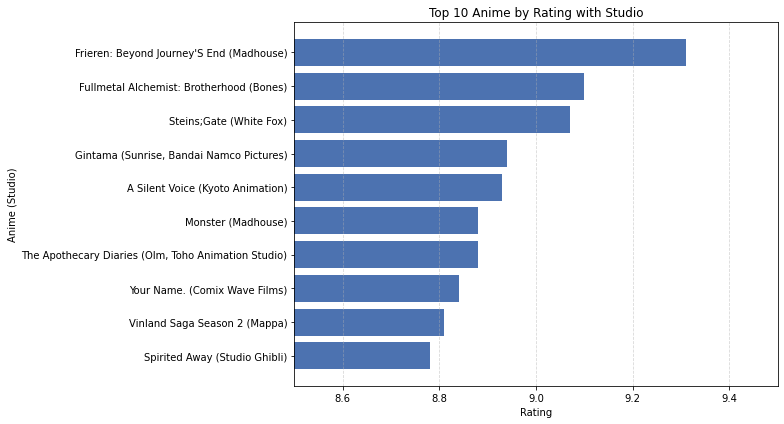

In [13]:
# Sort by rating (highest first); ties are broken by the higher episode count
top10 = (
    df.sort_values(by=["Rating", "Episodes"], ascending=[False, False])
    .head(10)
    .copy()
)

# Label each bar as "Anime Name (Studio)"
top10["Label"] = top10["Anime Name"] + " (" + top10["Studio"] + ")"

# Reverse the order so the highest rating appears at the top of the chart
plot_top10 = top10.iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(plot_top10["Label"], plot_top10["Rating"], color="#4C72B0")

# The x-axis starts at 8.5 (not 0) so that small differences are visible
ax.set_xlim(8.5, 9.5)
ax.set_title("Top 10 Anime by Rating with Studio")
ax.set_xlabel("Rating")
ax.set_ylabel("Anime (Studio)")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 4.4 Bar chart: top 8 genres
Counts how many anime carry each genre tag. An anime with several genres is counted once for each tag.

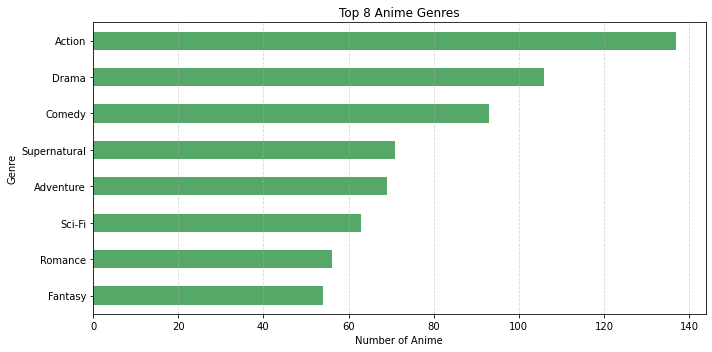

In [14]:
# Split "Action, Drama" into separate tags, one per row, then count each tag
top_genres = (
    df["Genre"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(8)
)

fig, ax = plt.subplots(figsize=(10, 5))
top_genres.sort_values().plot(kind="barh", ax=ax, color="#55A868")   # smallest at the bottom
ax.set_title("Top 8 Anime Genres")
ax.set_xlabel("Number of Anime")
ax.set_ylabel("Genre")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

---
## Summary
- The raw file was cleaned in five steps: text formatting, numeric conversion, release years, duplicates and missing values, and revenue parsing.
- Revenue was converted to USD millions and shared equally between co-producing studios.
- Four charts show studio revenue share, rating against release year, the top 10 rated anime, and the most common genres.